In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scipy
sc.settings.verbosity = 3
sc.logging.print_header()
sc.set_figure_params(dpi=100, dpi_save=600)
    
import scvelo as scv
scv.settings.verbosity = 3
scv.settings.presenter_view = True
scv.logging.print_versions()

import cellrank as cr
cr.settings.verbosity = 3
cr.logging.print_versions()

import matplotlib.pyplot as pl
from matplotlib import rcParams

import os

scanpy==1.8.2 anndata==0.7.8 umap==0.5.2 numpy==1.21.5 scipy==1.7.3 pandas==1.3.5 scikit-learn==1.0.2 statsmodels==0.13.1 python-igraph==0.9.9 pynndescent==0.5.5
scvelo==0.2.4  scanpy==1.8.2  anndata==0.7.8  loompy==3.0.6  numpy==1.21.5  scipy==1.7.3  matplotlib==3.5.1  sklearn==1.0.2  pandas==1.3.5  
cellrank==1.5.1 scanpy==1.8.2 anndata==0.7.8 numpy==1.21.5 numba==0.55.0 scipy==1.7.3 pandas==1.3.5 pygpcca==1.0.3 scikit-learn==1.0.2 statsmodels==0.13.1 python-igraph==0.9.9 scvelo==0.2.4 pygam==0.8.0 matplotlib==3.5.1 seaborn==0.11.2


In [2]:
# compare Muc2 clusters

In [3]:
raw = sc.read('C:/Users/Park_Lab/Documents/WIACIACT_raw.h5ad')
raw

AnnData object with n_obs × n_vars = 46313 × 32285
    obs: 'predicted_doublets', 'batch'
    var: 'gene_ids'

In [4]:
adata_sub2 = sc.read('C:/Users/Park_Lab/Documents/WIACIACT_adata_sub2.h5ad')
adata_sub2

AnnData object with n_obs × n_vars = 32178 × 5000
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'batch_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [5]:
raw.obs['leiden']=adata_sub2.obs['leiden']

In [6]:
adata=raw[raw.obs['leiden'].isin(['5', '9', '12'])]
adata

View of AnnData object with n_obs × n_vars = 4543 × 32285
    obs: 'predicted_doublets', 'batch', 'leiden'
    var: 'gene_ids'

normalizing counts per cell
    finished (0:00:00)


C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scanpy\preprocessing\_normalization.py:155: UserWarning: Revieved a view of an AnnData. Making a copy.
  view_to_actual(adata)


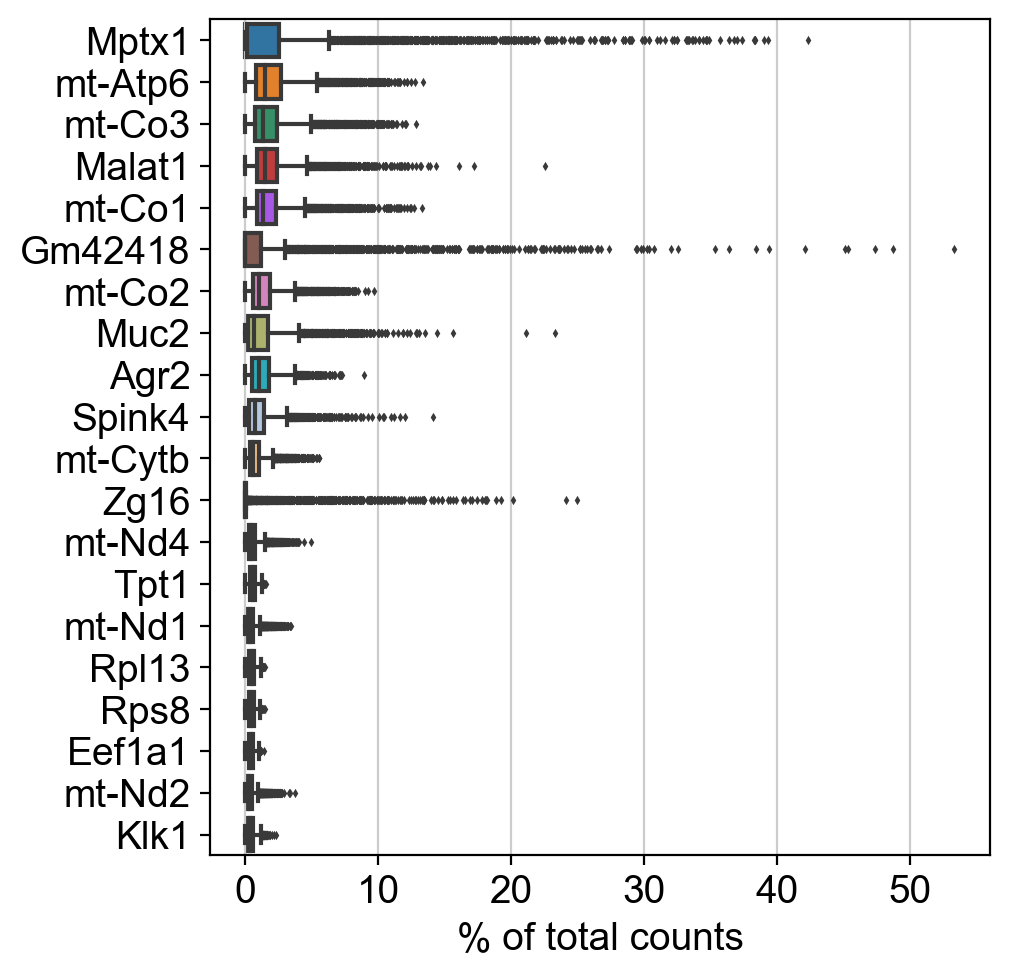

filtered out 20153 genes that are detected in less than 25 cells


AnnData object with n_obs × n_vars = 4543 × 12132
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes'
    var: 'gene_ids', 'n_cells'

In [7]:
sc.pl.highest_expr_genes(adata, n_top=20)
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=25)
adata

In [8]:
adata.var['mt'] = adata.var_names.str.startswith('mt-')
adata.var['rpl'] = adata.var_names.str.startswith('Rpl')
adata.var['rps'] = adata.var_names.str.startswith('Rps')
adata

AnnData object with n_obs × n_vars = 4543 × 12132
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps'

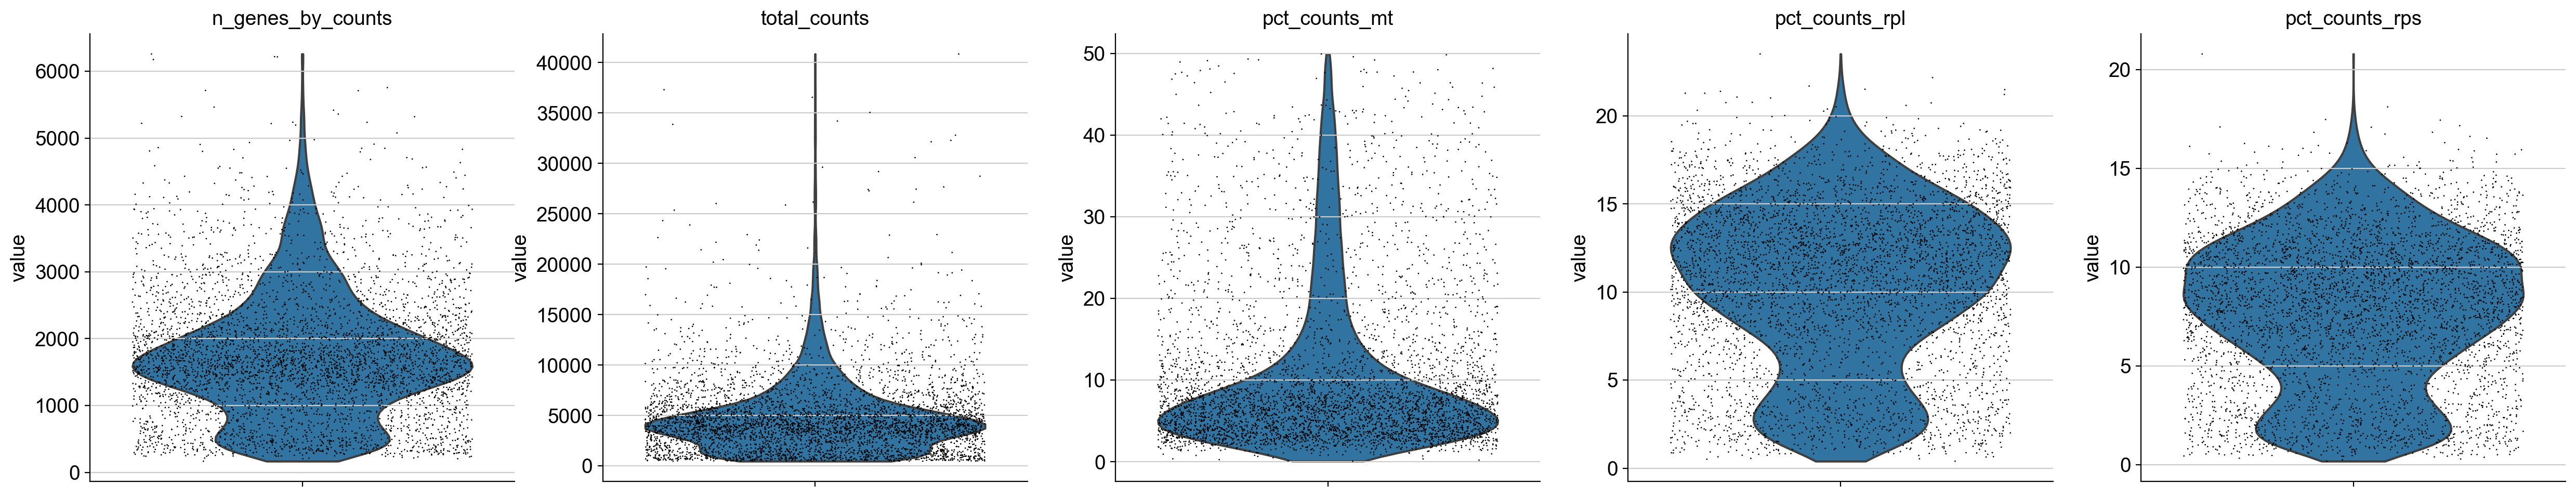

AnnData object with n_obs × n_vars = 4543 × 12132
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [9]:
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)
adata

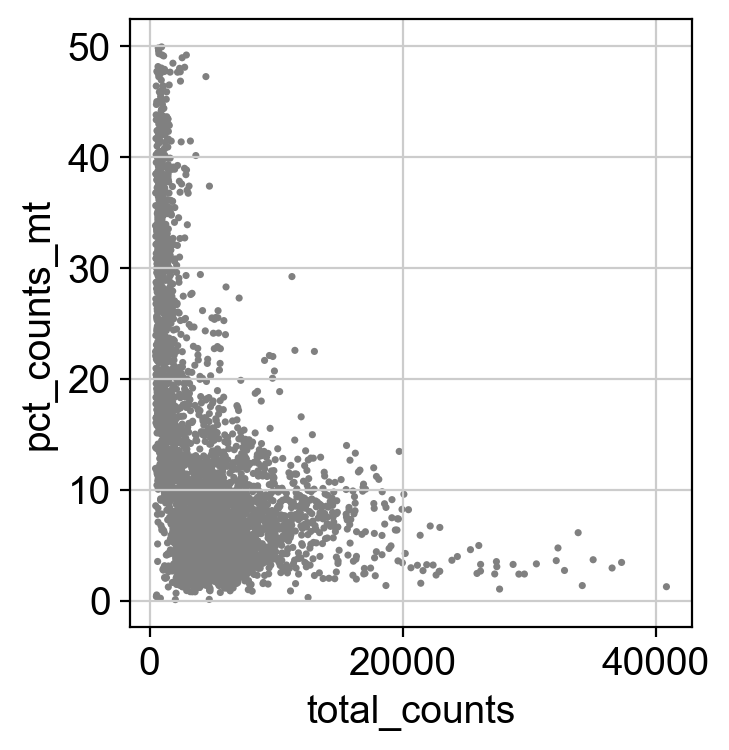

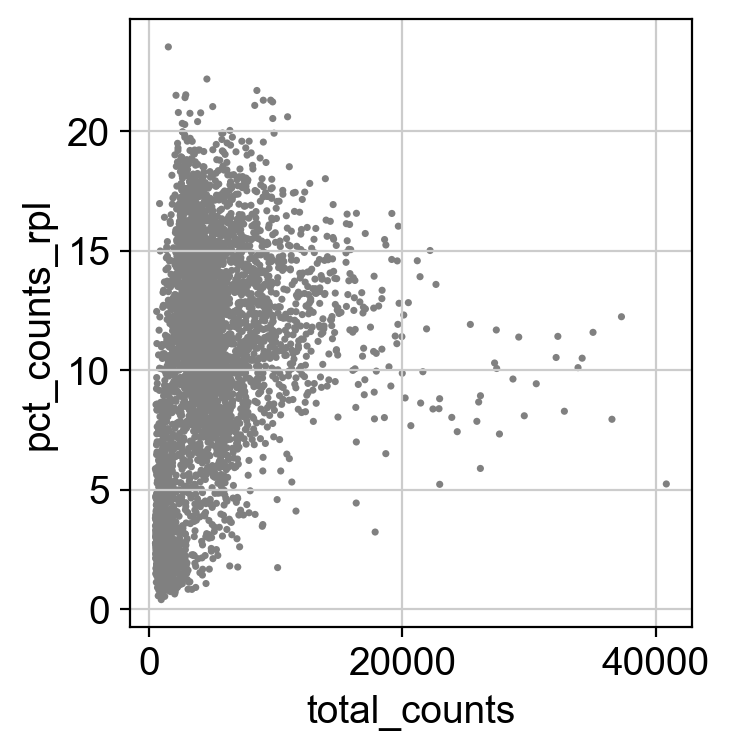

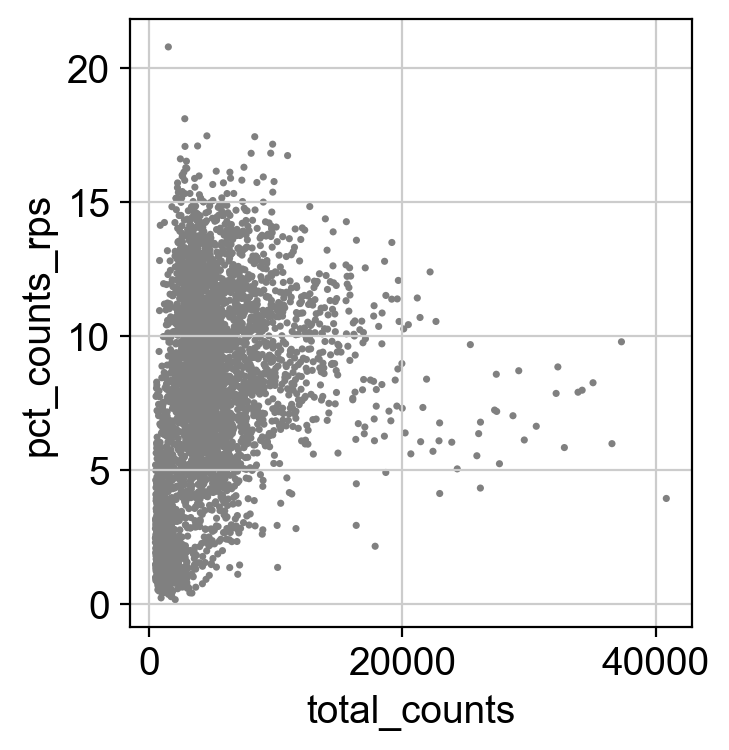

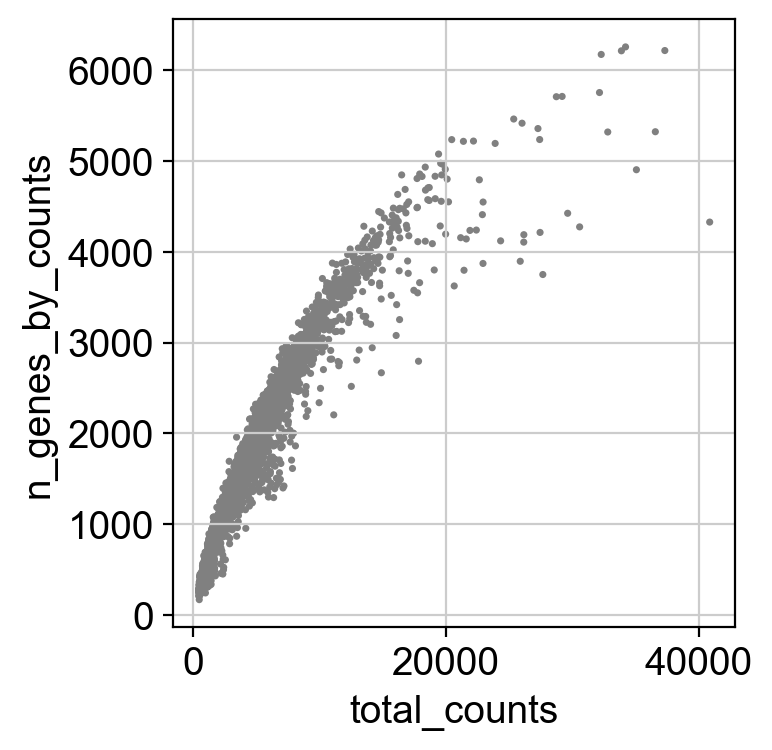

In [10]:
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_rpl')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_rps')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')

In [11]:
adata = adata[adata.obs.n_genes_by_counts < 8000, :]
adata = adata[adata.obs.pct_counts_mt < 50, :]
adata = adata[adata.obs.pct_counts_rpl < 50, :]
adata = adata[adata.obs.pct_counts_rps < 50, :]
adata

View of AnnData object with n_obs × n_vars = 4543 × 12132
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [12]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

normalizing counts per cell
    finished (0:00:00)


C:\Users\Park_Lab\anaconda3\envs\HYJ_py38\lib\site-packages\scanpy\preprocessing\_normalization.py:155: UserWarning: Revieved a view of an AnnData. Making a copy.
  view_to_actual(adata)


AnnData object with n_obs × n_vars = 4543 × 12132
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'

If you pass `n_top_genes`, all cutoffs are ignored.
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


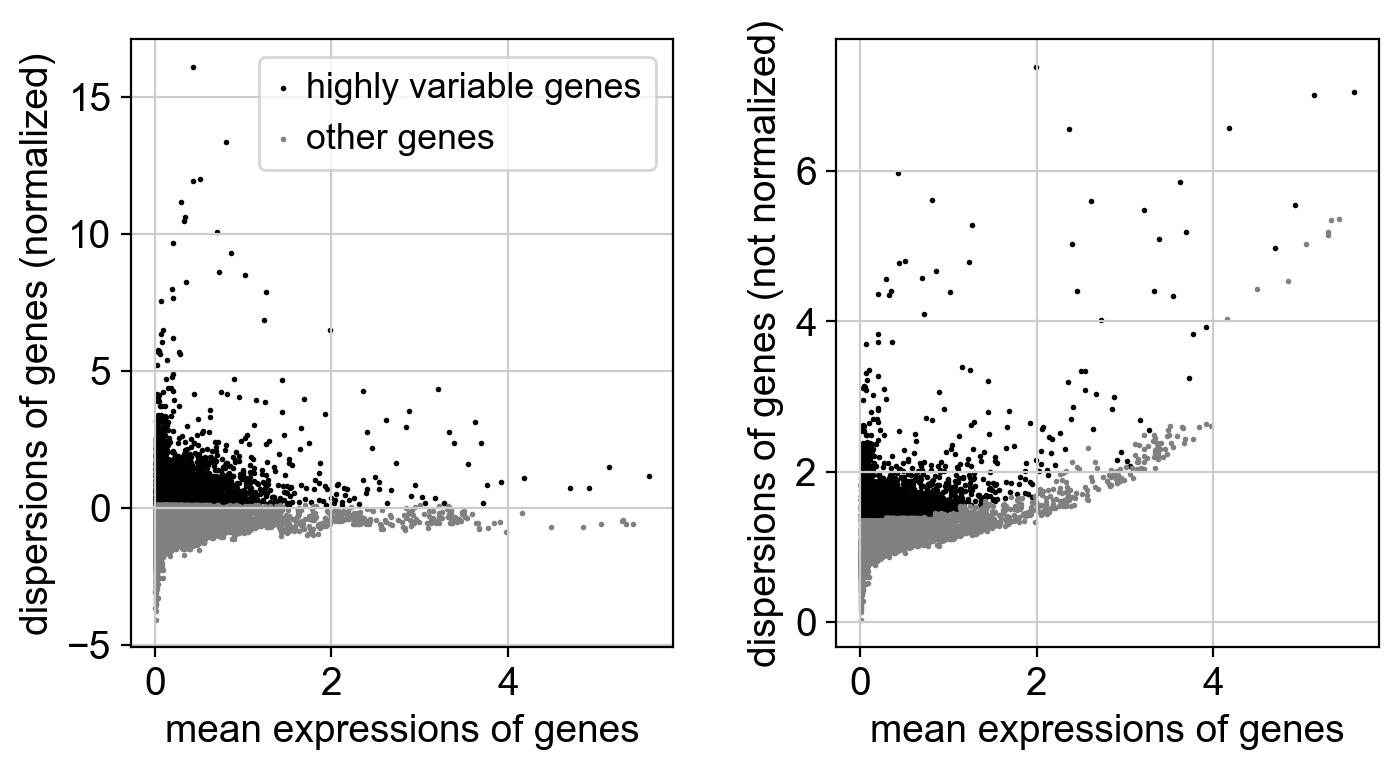

5000


AnnData object with n_obs × n_vars = 4543 × 12132
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [13]:
sc.pp.highly_variable_genes(adata, n_top_genes=5000)
sc.pl.highly_variable_genes(adata)
print(sum(adata.var.highly_variable))
adata

In [14]:
adata.raw=adata

In [15]:
adata = adata[:, adata.var.highly_variable]
adata

View of AnnData object with n_obs × n_vars = 4543 × 5000
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [16]:
sc.pp.regress_out(adata, keys=['total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], n_jobs=16)
sc.pp.scale(adata, max_value=10)
adata

regressing out ['total_counts', 'pct_counts_mt', 'pct_counts_rpl', 'pct_counts_rps']
    sparse input is densified and may lead to high memory use
    finished (0:00:15)


AnnData object with n_obs × n_vars = 4543 × 5000
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [17]:
sc.tl.pca(adata, svd_solver='arpack')
sce.pp.bbknn(adata, batch_key='batch')
sc.tl.leiden(adata, resolution=0.5)
sc.tl.umap(adata, n_components=3)
adata

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:02)
computing batch balanced neighbors
	finished: added to `.uns['neighbors']`
	`.obsp['distances']`, distances for each pair of neighbors
	`.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
running Leiden clustering
    finished: found 5 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:05)


AnnData object with n_obs × n_vars = 4543 × 5000
    obs: 'predicted_doublets', 'batch', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

Trying to set attribute `._uns` of view, copying.


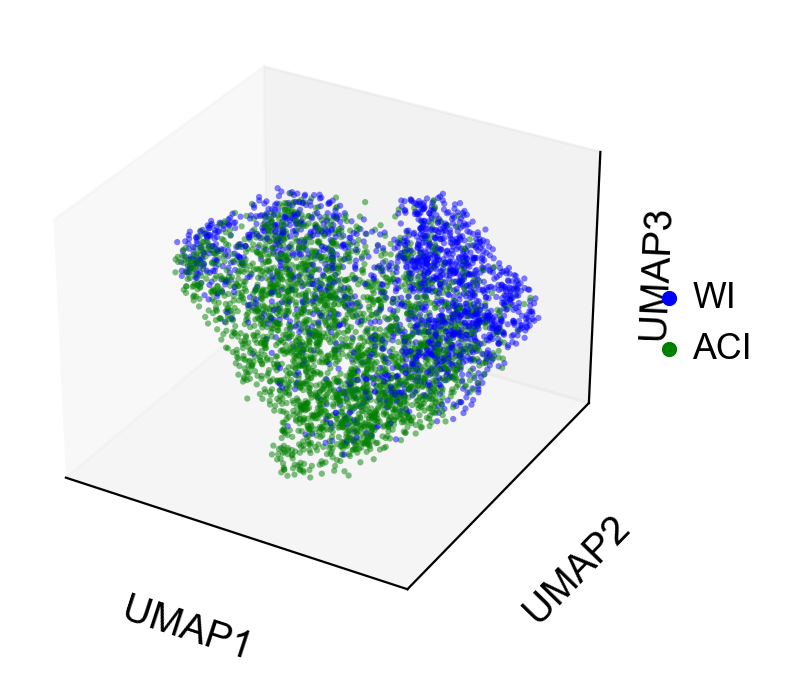

In [18]:
sc.pl.umap(adata[adata.obs['batch'].isin(['WI', 'ACI'])], color=['batch'], legend_loc='right margin', frameon=True, title='', use_raw=True, projection = '3d', alpha=0.5,
          palette={'WI': 'blue', 'ACI': 'green', 'ACT': 'red'}, save='1.pdf')

Trying to set attribute `._uns` of view, copying.


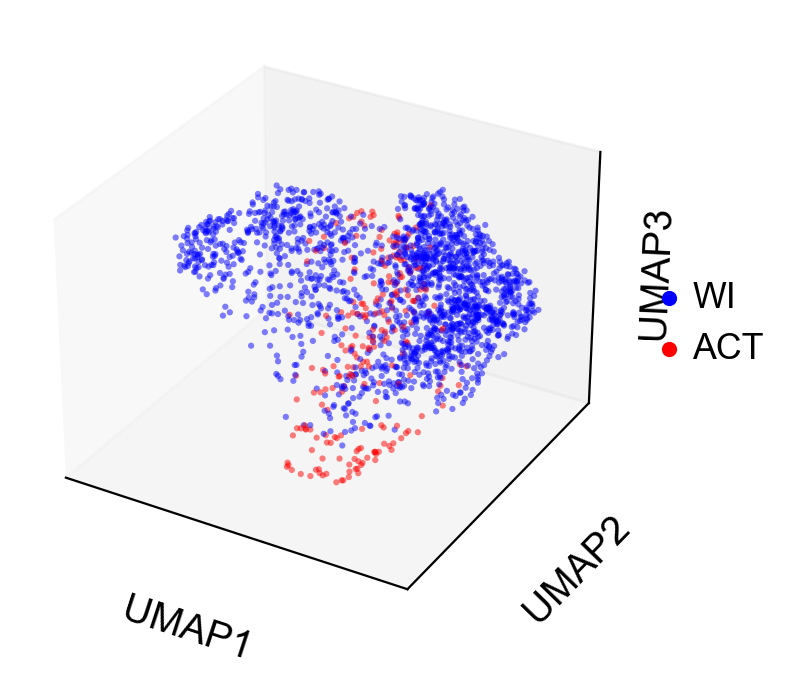

In [19]:
sc.pl.umap(adata[adata.obs['batch'].isin(['WI', 'ACT'])], color=['batch'], legend_loc='right margin', frameon=True, title='', use_raw=True, projection = '3d', alpha=0.5,
          palette={'WI': 'blue', 'ACI': 'green', 'ACT': 'red'}, save='2.pdf')

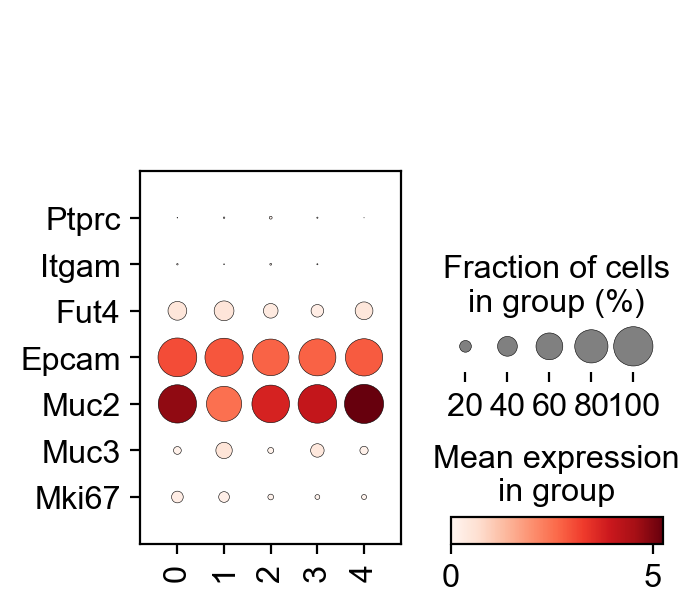

In [20]:
sc.pl.dotplot(adata, var_names=['Ptprc', 'Itgam', 'Fut4', 'Epcam', 'Muc2', 'Muc3', 'Mki67'], groupby='leiden', use_raw=True, var_group_rotation=0, vmin=0, swap_axes=True, dot_min=0)

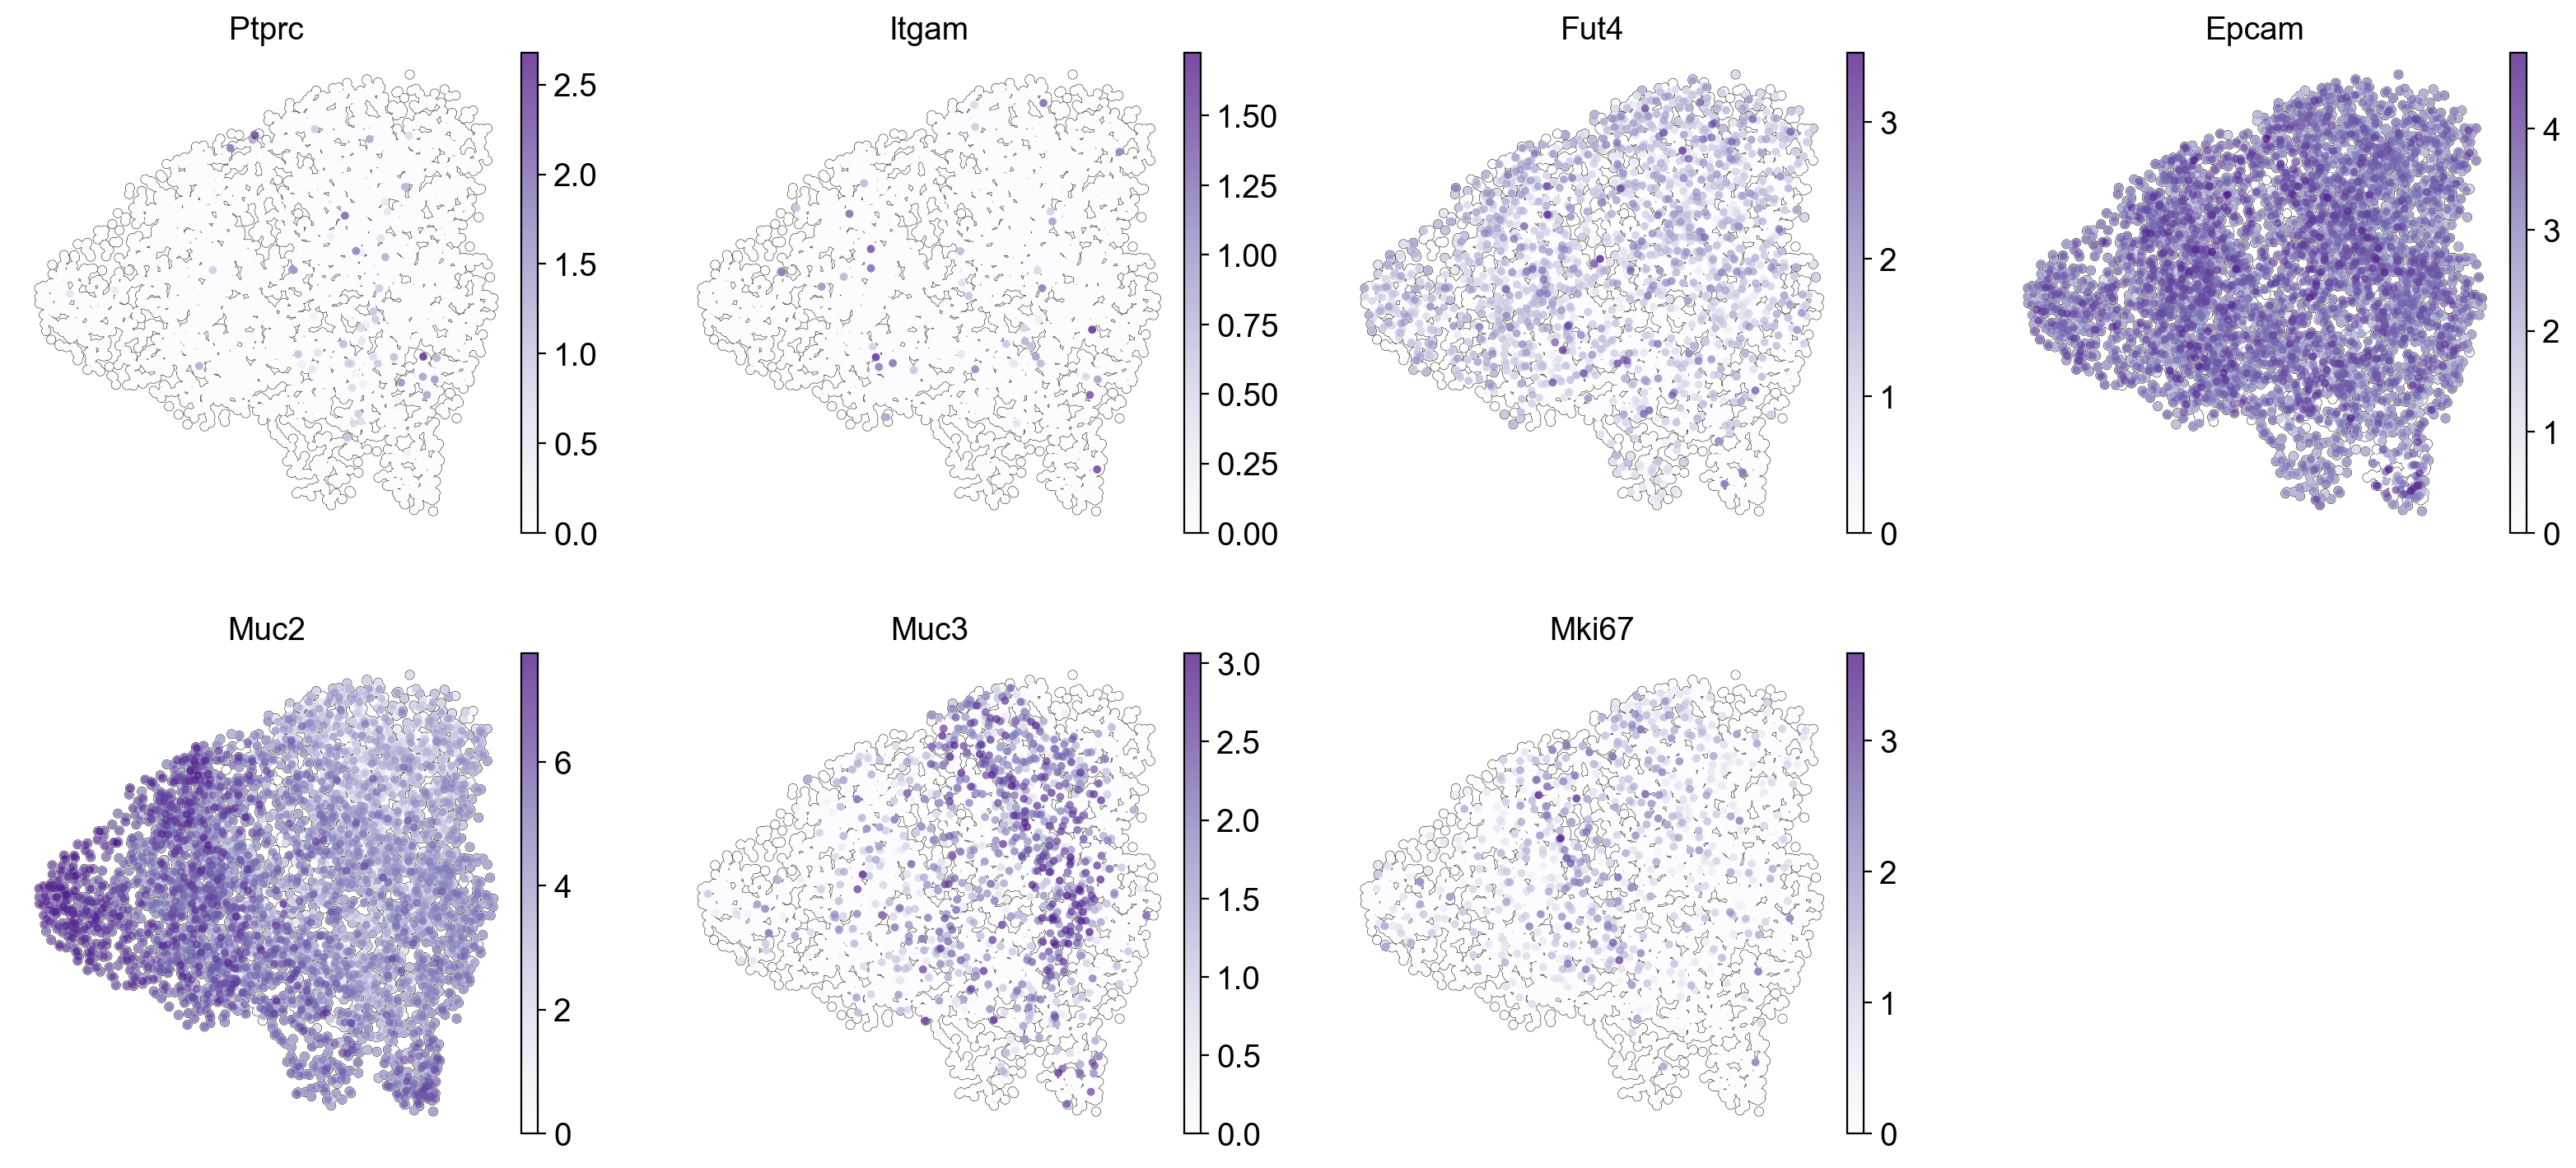

In [21]:
sc.pl.umap(adata, color=['Ptprc', 'Itgam', 'Fut4', 'Epcam', 'Muc2', 'Muc3', 'Mki67'], legend_loc='right margin', frameon=False, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='Purples')

In [22]:
sc.tl.rank_genes_groups(adata, groupby='batch', method='wilcoxon', use_raw=False)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:02)


In [23]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
pd.DataFrame(
  {group + '_' + key[:3]: result[key][group]
    for group in groups for key in ['names', 'scores', 'logfoldchanges', 'pvals_adj']}).to_csv("C:/Users/Park_Lab/Documents/Muc2_batch_markersforDrug.csv")

In [26]:
sc.tl.rank_genes_groups(adata, groupby='batch', groups=['ACI'], reference='WI', method='wilcoxon', use_raw=False)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:02)


In [27]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
pd.DataFrame(
  {group + '_' + key[:3]: result[key][group]
    for group in groups for key in ['names', 'scores', 'logfoldchanges', 'pvals_adj']}).to_csv("C:/Users/Park_Lab/Documents/Muc2_ACIvsWIforDrug.csv")

In [30]:
sc.tl.rank_genes_groups(adata, groupby='batch', groups=['ACT'], reference='WI', method='wilcoxon', use_raw=False)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


In [31]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
pd.DataFrame(
  {group + '_' + key[:3]: result[key][group]
    for group in groups for key in ['names', 'scores', 'logfoldchanges', 'pvals_adj']}).to_csv("C:/Users/Park_Lab/Documents/Muc2_ACTvsWIforDrug.csv")

In [32]:
adata.write('C:/Users/Park_Lab/Documents/WIACIACT_Muc2.h5ad', compression='gzip')